# 1. Initial setup
---
Installing dependencies and libraries as well as autoreloading modules and third-parties

In [114]:
# Installing dependencies for the analysis
%pip install pandas matplotlib openpyxl

Note: you may need to restart the kernel to use updated packages.


In [115]:
%reload_ext autoreload
%autoreload 2

# Importing all modules
import pandas as pd
import matplotlib as mlt
import matplotlib.pyplot as plt
import openpyxl as xl
from openpyxl import load_workbook
import math
from openpyxl.styles import PatternFill
from visualise import *

# Additional variables
SEVERITY = {
    'F8CBAD':'high', 
    'FEF802':'medium', 
    '92D050':'low', 
    'BDD7EE':'info', 
    'F60000':'critical', 
    '000000': None,
    'AEAAAA':'FP' # False Positives
}

In [117]:
PATH="Results.Final.xlsx"

# 2. Data Cleaning
---

Clean the dataset to make sure the data points are consistent and accurate before proceeding. I guess it's a good practice to use `openpyxl` to make the cleaning process possible.

In [119]:
PATH_RAW="Results.I4.xlsx"
wb = load_workbook(PATH_RAW)

## I1 - Normalise all severity colors within the `New Bugs` sheet
Some of the cells possess a mismatch in color, such as using a theme/tint color. This can introduce difficulties comparing and evaluating severities later on.

In [120]:
# Normalise the severity rating colors
NBUGS = wb["New bugs"]
RESULTS = pd.read_excel(PATH_RAW, sheet_name="Results")
RESULTS.iloc[1:33, 3:13].stack().unique()
for row in NBUGS.iter_rows(min_row=3, max_row=51, min_col=2, max_col=14):
    for cell in row:
        color = cell.fill.fgColor

        if (
            color.type == "theme"
            and color.theme == 5
            and abs((color.tint or 0) - 0.5999) < 0.0001
        ):
            cell.fill = PatternFill(fill_type="solid", fgColor="F8CBAD")

wb.save("Results.Test.xlsx")

# Ensuring that all colors are valid now
PATH_TEST="Results.Test.xlsx"
wb = load_workbook(PATH_TEST, data_only=True)
NBUGS = wb["New bugs"]
for row in NBUGS.iter_rows(min_row=3, max_row=51, min_col=2, max_col=14):
    for cell in row:
        color = cell.fill.fgColor
        if color.type=="theme":
            raise Exception("Invalid severity color")
        elif color.type=="rgb":
            colorRgb = color.rgb[2:]
            SEVERITY[colorRgb]

__import__("os").remove(PATH_TEST)
print("OK")

OK


In [121]:
# # Normalise the severity rating colors again
# NBUGS = wb["New bugs"]

# for row in NBUGS.iter_rows(min_row=3, max_row=51, min_col=2, max_col=14):
#     for cell in row:
#         color = cell.fill.fgColor

#         if (
#             color.type == "theme"
#             and color.theme == 5
#             # and abs((color.tint or 0) - 0.5999) < 0.0001
#         ):
#             cell.fill = PatternFill(fill_type="solid", fgColor="F8CBAD")

# wb.save("Results.I4.xlsx")

# # Ensuring that all colors are valid now
# PATH="Results.I4.xlsx"
# wb = load_workbook(PATH, data_only=True)
# NBUGS = wb["New bugs"]
# for row in NBUGS.iter_rows(min_row=3, max_row=51, min_col=2, max_col=14):
#     for cell in row:
#         color = cell.fill.fgColor
#         if color.type=="theme":
#             raise Exception("Invalid severity color")
#         elif color.type=="rgb":
#             colorRgb = color.rgb[2:]
#             SEVERITY[colorRgb]
# print("OK")

## I2 - Lowercase all severities within the `Results` sheet.
Just to make everything consistent according to a common format, I will lowercase all severities and check for any malformed data points within the dataset

In [122]:
RESULTS = wb["Results"]

unique_values = set()

for row in RESULTS.iter_rows(min_row=2, max_row=33, min_col=4, max_col=13):
    for cell in row:
        # Lowercase hardcoded text only; leave formulas, numbers, colours, etc. unchanged
        if isinstance(cell.value, str):
            unique_values.add(cell.value.lower())
            cell.value = cell.value.lower()
            
print(unique_values)

{'low', 'critical', 'high', 'info', 'medium'}


## I2 - Lowercase all new bugs, replace empty strings, redundant cells and trim all texts
Manual cleaning has already been done to normalised all repetitive vulnerabilities into one specific category.

In [123]:
ws = wb["New bugs"]

# Loop through B3:J51
for row in ws.iter_rows(
    min_row=3, max_row=51,
    min_col=2, max_col=10,
):
    for cell in row:
        value = cell.value
        if (isinstance(value, str) and value=='') or value=="s": # for some weird reasons, there is always one redundant "s" within the sheet.
            cell.value = None
        elif isinstance(value, str):
            cell.value = value.strip().lower()

In [124]:
# Saving the results as Results.Final.xlsx
wb.save("Results.Final.xlsx")

# 3. Data transformation
---
The section below is dedicated to transforming and converting the dataset into a collection of easily representative visualisations. The point is to construct sub-datasets suitable for the following purposes:

1. Efficiency evaluation between LLMs
2. Consistency evaluation between LLMs
3. Additional findings

In [136]:
# Run this first
import re

# DataFrames to be manipulated
df =  pd.read_excel(PATH)
df_cost = pd.read_excel(PATH, sheet_name="LLM cost")
df_results = pd.read_excel(PATH, sheet_name="Results")
df_new_bugs = pd.read_excel(PATH, sheet_name="New bugs")

# Manipulating Excel files using openpyxl
wb_new_bugs = load_workbook(PATH)
new_bugs = wb_new_bugs['New bugs']

## 3.1 Data subset for time taken per LLM

In [130]:
def time_to_minutes(value):
    # Convert "00m 00s" to minute in floating point
    match = re.fullmatch(r"\s*(?:(\d+(?:\.\d+)?)m)?\s*(?:(\d+(?:\.\d+)?)s)?\s*",str(value),)
    if not match:
        raise ValueError(f"Invalid time format: {value!r}")
    return float(match.group(1) or 0) + float(match.group(2) or 0) / 60

df_cost_time = df_cost[["Model", "Time"]].copy().dropna()
df_cost_time["Time"] = df_cost_time["Time"].apply(time_to_minutes)
TIME_ITERATIONS = {
    "Claude":df_cost_time.loc[9:17, "Time"],
    "DeepSeek":df_cost_time.loc[0:8, "Time"],
    "Grok":df_cost_time.loc[18:26, "Time"]
}
TIME_ITERATIONS

{'Claude': 9      67.566667
 10     56.750000
 11     46.883333
 12     64.300000
 13     63.350000
 14     24.466667
 15     90.466667
 16    117.750000
 17     62.200000
 Name: Time, dtype: float64,
 'DeepSeek': 0    34.083333
 1    36.583333
 2    74.250000
 3    31.783333
 4    20.483333
 5    36.500000
 6    35.800000
 7    43.633333
 8    27.916667
 Name: Time, dtype: float64,
 'Grok': 18     39.033333
 19     38.716667
 20    124.316667
 21     40.483333
 22     38.766667
 23     35.300000
 24     50.416667
 25    655.716667
 26     28.316667
 Name: Time, dtype: float64}

## 3.2 Data subset for cost taken per LLM

In [131]:
COST_ITERATIONS = {
    "Claude":df_cost.loc[9:17, "Cost (AUD)"],
    "DeepSeek":df_cost.loc[0:8, "Cost (AUD)"],
    "Grok":df_cost.loc[18:26, "Cost (AUD)"]
}
COST_ITERATIONS

{'Claude': 9     14.154
 10    14.266
 11    13.594
 12    14.672
 13    19.978
 14    16.716
 15    13.818
 16    14.686
 17    12.180
 Name: Cost (AUD), dtype: float64,
 'DeepSeek': 0     1.022
 1     1.092
 2     1.288
 3     0.588
 4    15.652
 5     0.672
 6     0.994
 7     0.952
 8     0.630
 Name: Cost (AUD), dtype: float64,
 'Grok': 18    4.858
 19    4.928
 20    4.326
 21    4.802
 22    6.188
 23    4.718
 24    9.716
 25    4.200
 26    3.808
 Name: Cost (AUD), dtype: float64}

## 3.3 Data subset for benchmarking expected findings between LLMs

In [132]:
from collections import defaultdict

VALID_SEVERITY = []
INVALID_SEVERITY = []
MISSED_BUGS = []
TOTAL_BUGS = df_results['Severity'].notna().sum()

for col in df_results.columns[4:13]:
    VALID_SEVERITY.append((df_results[col].notna() & df_results[col].eq(df_results['Severity'])).sum())
    INVALID_SEVERITY.append((df_results[col].notna() & df_results[col].ne(df_results['Severity'])).sum())
    MISSED_BUGS.append((df_results[col].isna()).sum())
    # print(invalidSeverity, validSeverity, missedBugs, missedBugs + validSeverity + invalidSeverity)

## 3.4 Data subset for new bugs discovery

In [133]:
# A list of all new bugs discovered across three companies, three iterations and three models.
all_new_bugs = pd.unique(df_new_bugs.iloc[1:50, 1:10].to_numpy().ravel())
all_valid_bugs = set()

is_Valid_bug = lambda cell: \
    (not cell.font.bold) and \
    (not cell.font.italic) and \
    (str(cell.fill.fgColor.rgb)[-6:].upper() not in ["AEAAAA", "000000"]) and \
    (cell.value is not None) and \
    (cell.value != '')

def count_bugs_found(section):
    global all_valid_bugs
    
    ret = {
        'DeepSeek V4 Pro':[0,0,0],
        'Claude Opus 4.7':[0,0,0],
        'Grok 4.6':[0,0,0]
    }
    for row in section:

        for col in row: 
            if is_Valid_bug(col):
                all_valid_bugs.add(col.value)
        
        ret['DeepSeek V4 Pro'][0] += is_Valid_bug(row[0])
        ret['DeepSeek V4 Pro'][1] += is_Valid_bug(row[1])
        ret['DeepSeek V4 Pro'][2] += is_Valid_bug(row[2])
        ret['Grok 4.6'][0] += is_Valid_bug(row[3])
        ret['Grok 4.6'][1] += is_Valid_bug(row[4])
        ret['Grok 4.6'][2] += is_Valid_bug(row[5])
        ret['Claude Opus 4.7'][0] += is_Valid_bug(row[6])
        ret['Claude Opus 4.7'][1] += is_Valid_bug(row[7])
        ret['Claude Opus 4.7'][2] += is_Valid_bug(row[8])
    return ret 

MOST_NEW_BUGS = {
    "AuSecurity": count_bugs_found(new_bugs['B3:J18']),
    "Imagur": count_bugs_found(new_bugs['B36:J51']),
    "DownUnderNews": count_bugs_found(new_bugs['B19:J35'])
}
MOST_NEW_BUGS

{'AuSecurity': {'DeepSeek V4 Pro': [7, 10, 8],
  'Claude Opus 4.7': [12, 14, 16],
  'Grok 4.6': [9, 11, 5]},
 'Imagur': {'DeepSeek V4 Pro': [3, 5, 6],
  'Claude Opus 4.7': [8, 14, 8],
  'Grok 4.6': [10, 8, 8]},
 'DownUnderNews': {'DeepSeek V4 Pro': [7, 4, 8],
  'Claude Opus 4.7': [15, 7, 7],
  'Grok 4.6': [6, 8, 10]}}

## 3.5 Data subset for severity rating, out-of-scope and false positives accuracy
Construct a valid format to visualise the accuracy between severity rating and hallucinations of each LLM

In [164]:
wb = load_workbook(PATH, data_only=True)
source = wb["New bugs"]

# Match bug names regardless of capitalisation or surrounding spaces
def normalise(value):
    return str(value).strip().lower()


# O1:P1 contains headers; O2:P67 contains the vulnerability dataset
records = [
    (bug, severity)
    for bug, severity in source.iter_rows(
        min_row=2, max_row=67,
        min_col=15, max_col=16,
        values_only=True
    )
    if bug is not None and str(bug).strip()
]

df_new_bugs = pd.DataFrame(records, columns=["Bug", "Severity"])
df_new_bugs.insert(0, "ID", range(1, len(df) + 1))

# Add the 9 model/iteration columns
iteration_columns = ["DeepSeek I1", "DeepSeek I2","DeepSeek I3","Grok I1","Grok I2","Grok I3","Claude I1","Claude I2","Claude I3"]  

for column in iteration_columns:
    df_new_bugs[column] = pd.Series(pd.NA, index=df_new_bugs.index, dtype="object")

# Map each bug name to its DataFrame row
bug_names = df_new_bugs["Bug"].map(normalise)

if bug_names.duplicated().any():
    raise ValueError("Duplicate bug names found in column O.")

bug_to_row = dict(zip(bug_names, df_new_bugs.index))
counts = {
    column: {"False positives": 0, "Out of scope": 0}
    for column in iteration_columns
}

for column_name, cells in zip(
    iteration_columns,
    source.iter_cols(
        min_col=2, max_col=10,
        min_row=3, max_row=51
    )
):
    for cell in cells:
        if cell.value is None or not str(cell.value).strip():
            continue

        colour = cell.fill.fgColor
        hex_colour = (
            colour.rgb[-6:].upper()
            if colour.type == "rgb"
            else None
        )

        is_fp = hex_colour == "AEAAAA"
        is_out_of_scope = bool(cell.font.bold and cell.font.italic)

        # Count before excluding
        counts[column_name]["False positives"] += int(is_fp)
        counts[column_name]["Out of scope"] += int(is_out_of_scope)

        if is_fp or is_out_of_scope:
            continue

        if colour.type != "rgb":
            raise ValueError(
                f"{cell.coordinate} uses {colour.type} colour; "
                "convert its background to RGB first."
            )

        if hex_colour not in SEVERITY:
            raise ValueError(
                f"Unknown background colour at "
                f"{cell.coordinate}: {hex_colour}"
            )

        bug_name = normalise(cell.value)

        if bug_name not in bug_to_row:
            raise ValueError(
                f"Bug at {cell.coordinate} is missing from column O: "
                f"{cell.value!r}"
            )

        row_index = bug_to_row[bug_name]
        df_new_bugs.at[row_index, column_name] = SEVERITY[hex_colour]

df_new_bugs['Severity'] = df_new_bugs['Severity'].str.lower()

# Separate summary DataFrame: one row per model/iteration
counts_df = pd.DataFrame.from_dict(counts, orient="index")
counts_df.index.name = "Model / iteration"

display(df_new_bugs.style.format(na_rep=""))
display(counts_df)

,ID,Bug,Severity,DeepSeek I1,DeepSeek I2,DeepSeek I3,Grok I1,Grok I2,Grok I3,Claude I1,Claude I2,Claude I3
0,1,?author=n and wp-links-opml.php endpoints expose administrator username,low,,,,,,,,,medium
1,2,apache site exposed on port 8080 via cleartext,medium,,medium,,low,,medium,medium,high,high
2,3,wordpress directory listing enabled,medium,medium,medium,low,medium,medium,,medium,medium,medium
3,4,wordpress user enumeration enabled,medium,medium,medium,low,,,,medium,medium,
4,5,ssh service uses legacy mac algorithms,info,,,,,,,medium,,
5,6,admin login does not have rate limiting,low,,,,,,,critical,medium,
6,7,account enumeration via registration,low,medium,,medium,,,,,medium,medium
7,8,weak and shared administrator credentials,low,,,low,,,,,,
8,9,/api path redirects to http,medium,,,,,,medium,,,
9,10,pii exposure on admin dashboard,medium,high,,,medium,medium,,,high,


,False positives,Out of scope
Model / iteration,,
DeepSeek I1,1,1
DeepSeek I2,0,1
DeepSeek I3,0,0
Grok I1,0,0
Grok I2,1,1
Grok I3,1,1
Claude I1,2,3
Claude I2,2,4
Claude I3,2,2


In [143]:
# from collections import defaultdict

# # data subsets
# claude_dataset = new_bugs["H3:J51"]
# deepseek_dataset = new_bugs["B3:D51"]
# grok_dataset = new_bugs["E3:G51"]

# # Functions to build datasets
# # benchmark_truths = dict(zip(df["New bugs"], df["New severity"].str.strip().str.lower()))
# is_Valid_bug = lambda cell: \
#     (not cell.font.bold) and \
#     (not cell.font.italic) and \
#     (str(cell.fill.fgColor.rgb)[-6:].upper() not in ["AEAAAA", "000000"]) and \
#     (cell.value is not None) and \
#     (cell.value != '')

# def false_positives():
#     falseps = lambda dataset:sum([sum([SEVERITY[str(cell.fill.fgColor.rgb)[-6:].upper()] == "false_positives" for cell in row]) for row in dataset])
#     return [ falseps(claude_dataset), falseps(deepseek_dataset), falseps(grok_dataset) ]
    
# def outofscope(): 
#     outofscope = lambda dataset:sum([sum([(cell.font.italic and cell.font.bold) for cell in row]) for row in dataset])
#     return [ outofscope(claude_dataset), outofscope(deepseek_dataset), outofscope(grok_dataset) ]

# def validSeverity():
#     validSev = lambda dataset:sum([sum([ is_Valid_bug(cell) and SEVERITY[str(cell.fill.fgColor.rgb)[-6:].upper()]==benchmark_truths[cell.value.strip()] for cell in row]) for row in dataset])
#     return [ validSev(claude_dataset), validSev(deepseek_dataset), validSev(grok_dataset)]

# def invalidSeverity():
#     validSev = lambda dataset:sum([sum([ is_Valid_bug(cell) and SEVERITY[str(cell.fill.fgColor.rgb)[-6:].upper()]!=benchmark_truths[cell.value.strip()] for cell in row]) for row in dataset])
#     return [ validSev(claude_dataset), validSev(deepseek_dataset), validSev(grok_dataset)]

# def uniqueBugs():
#     def get_set_per_set(dataset):
#         set_ = set()
#         for col in dataset:
#             for cell in col: 
#                 if is_Valid_bug(cell):
#                     set_.add(cell.value)
#         return set_
    
#     claude = get_set_per_set(claude_dataset)
#     grok = get_set_per_set(grok_dataset)
#     deepseek = get_set_per_set(deepseek_dataset)

#     claude_compare = grok.union(deepseek)
#     deepseek_compare = claude.union(grok)
#     grok_compare = deepseek.union(claude)

#     unique_claude = set([i if i not in claude_compare else None for i in claude])
#     unique_deepseek = set([i if i not in deepseek_compare else None for i in deepseek])
#     unique_grok = set([i if i not in grok_compare else None for i in grok])
#     unique_claude.remove(None)
#     unique_deepseek.remove(None)
#     unique_grok.remove(None)
    
#     return [
#         len(unique_claude),
#         len(unique_deepseek),
#         len(unique_grok)
#     ]

# Data points to fetch into the visualisation function later
# groups = ["Claude Opus 4.7", "DeepSeek V4 Pro", "Grok 4.6"]
# TOTAL_BUGS = [
#     sum([ sum([((cell.value is not None) and (cell.value != '')) for cell in col]) for col in claude_dataset]),
#     sum([ sum([((cell.value is not None) and (cell.value != '')) for cell in col]) for col in deepseek_dataset]),
#     sum([ sum([((cell.value is not None) and (cell.value != '')) for cell in col]) for col in grok_dataset])
# ]


# SEVERITY_FALSE_POS_UNIQUE_RATING = {
#     "False positives": false_positives(),
#     "Out of scope": [1,2,3],
#     "Findings with valid severity": [1,2,3],
#     "Findings with invalid severity": [1,2,3],
#     "Unique bugs": [1,3,4],
# }
# TOTAL_BUGS

,ID,New bug,New severity,Extra 1,Extra 2,Extra 3,Extra 4,Extra 5,Extra 6,Extra 7,Extra 8,Extra 9
0,1,?author=n and wp-links-opml.php endpoints expo...,Low,None,None,None,None,None,None,None,None,None
1,2,apache site exposed on port 8080 via cleartext,Medium,None,None,None,None,None,None,None,None,None
2,3,wordpress directory listing enabled,Medium,None,None,None,None,None,None,None,None,None
3,4,wordpress user enumeration enabled,Medium,None,None,None,None,None,None,None,None,None
4,5,ssh service uses legacy mac algorithms,Info,None,None,None,None,None,None,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...
61,62,weak password policy,Low,None,None,None,None,None,None,None,None,None
62,63,registration email check is not enforced,Low,None,None,None,None,None,None,None,None,None
63,64,osticket installer exposed,High,None,None,None,None,None,None,None,None,None
64,65,/api/health exposed,Low,None,None,None,None,None,None,None,None,None


# 4. Visualisation / Analysis
---
Extracting core details on what insights we can have and analyse from these visualisations between `Claude Opus 4.7`, `DeepSeek V4 Pro` and `Grok 4.6`.

## 4.1 Benchmark expected findings rate between LLMs
Which model performs best when it comes to finding intentional bugs and whether the severity rating is accurate.

> `QUESTION`: How many matched the severity rating, how many didn’t and how many missed the intended bugs ?
>
> `NOTE`: Despite lower discovery rate of intentional bugs compared to DeepSeek V4 Pro, Claude Opus 4.7 was the only model that managed to find a chained vulnerability which turn Low-severity self-XSS into High-severity Stored-XSS via IDOR. 

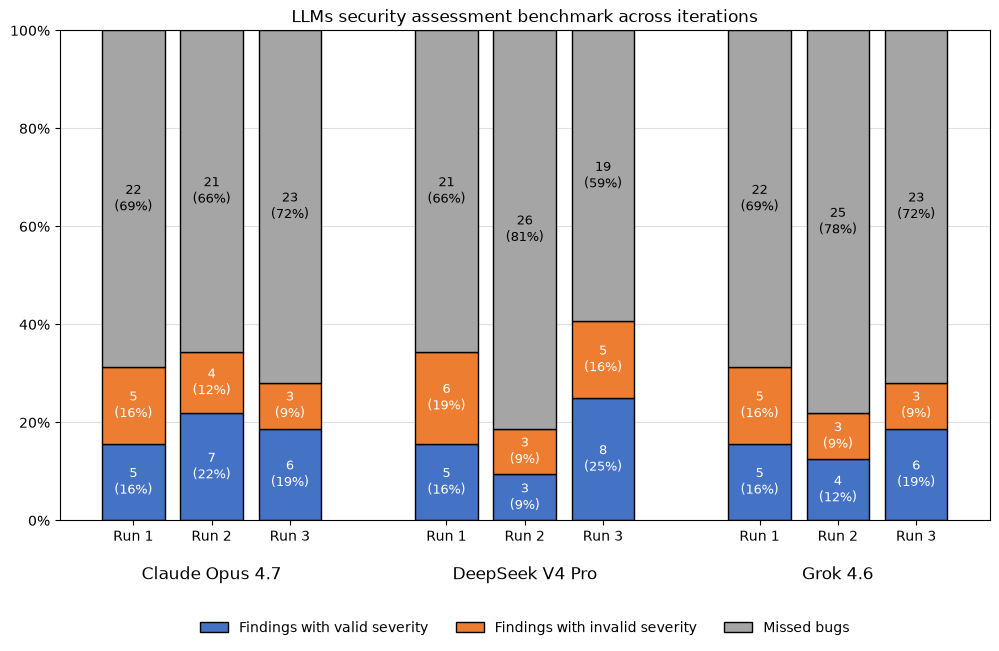

(<Figure size 1200x700 with 1 Axes>,
 <Axes: title={'center': 'LLMs security assessment benchmark across iterations'}>)

In [254]:
LABELS = ["Claude Opus 4.7", "DeepSeek V4 Pro", "Grok 4.6"] 
data = {
    "Findings with valid severity":  VALID_SEVERITY,
    "Findings with invalid severity": INVALID_SEVERITY,
    "Missed bugs": MISSED_BUGS,
}

stacked_bar_groups_percent(
    LABELS,
    ["Run 1", "Run 2", "Run 3"],
    data,
    total=TOTAL_BUGS,
    title="LLMs security assessment benchmark across iterations"
)

## 4.1 Which LLMs discover the most new bugs ?

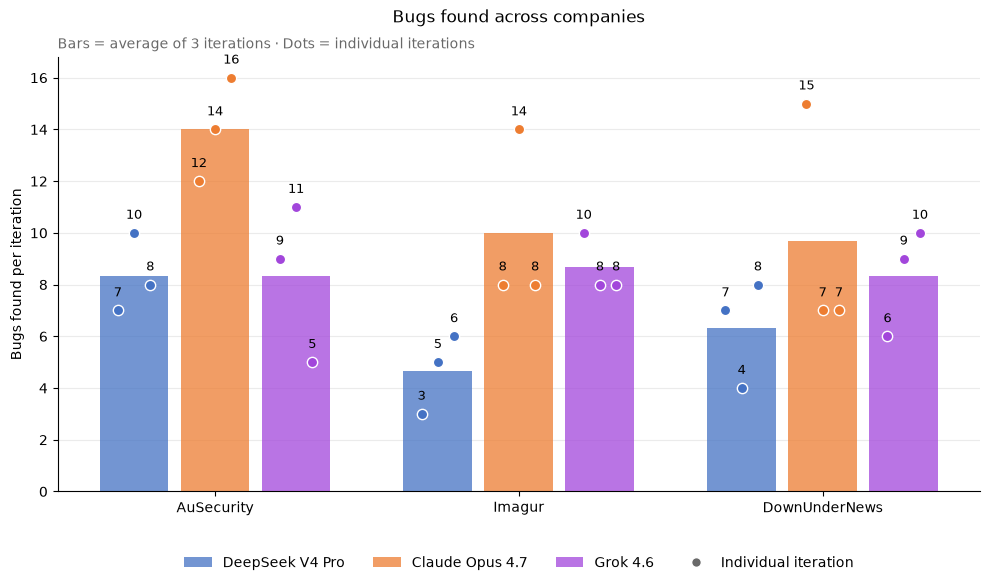

In [330]:
fig, ax = group_barchart_with_average(MOST_NEW_BUGS)

# Optional: save the chart.
fig.savefig("bug_discovery.png", dpi=300, bbox_inches="tight")

plt.show()

## 4.2 Benchmark the capabilities to discover new bugs between LLMs

Which model experiences the most false-positives / hallucinations, out-of-scoped items, bug uniqueness, and severity correctness.

> `QUESTION`: Across all overlapping bugs, which model possesses the highest rate of bug uniqueness across three flagship models. This means which one among them manages to discover bugs that are completely unique to the rest, where the other two models failed to discover such findings ? Additionally, talk about the severity of those bugs as well.

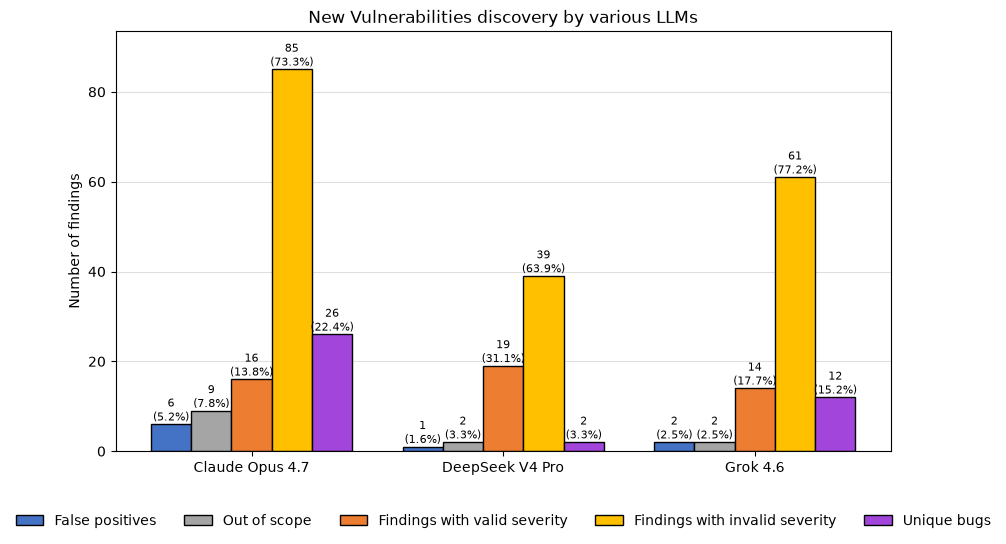

In [478]:
groups = ["Claude Opus 4.7", "DeepSeek V4 Pro", "Grok 4.6"]

totals = [100,50,60]

fig, ax = grouped_bar_chart(
    groups=groups,
    data=SEVERITY_FALSE_POS_UNIQUE_RATING,
    totals=TOTAL_BUGS,
    title="New Vulnerabilities discovery by various LLMs"
)

## 4.2 Benchmark the cost between LLMs

Which model produces the cheapest cost overall, as well as the average cost ?

> INCIDENT: The outlier for DeepSeek V4 Pro was actually an incident where DeepSeek hang forever whilst during the second iteration of company 3. It wiped out the balance and took over 15.652$ AUD and had to be manually stopped before retrying again. 

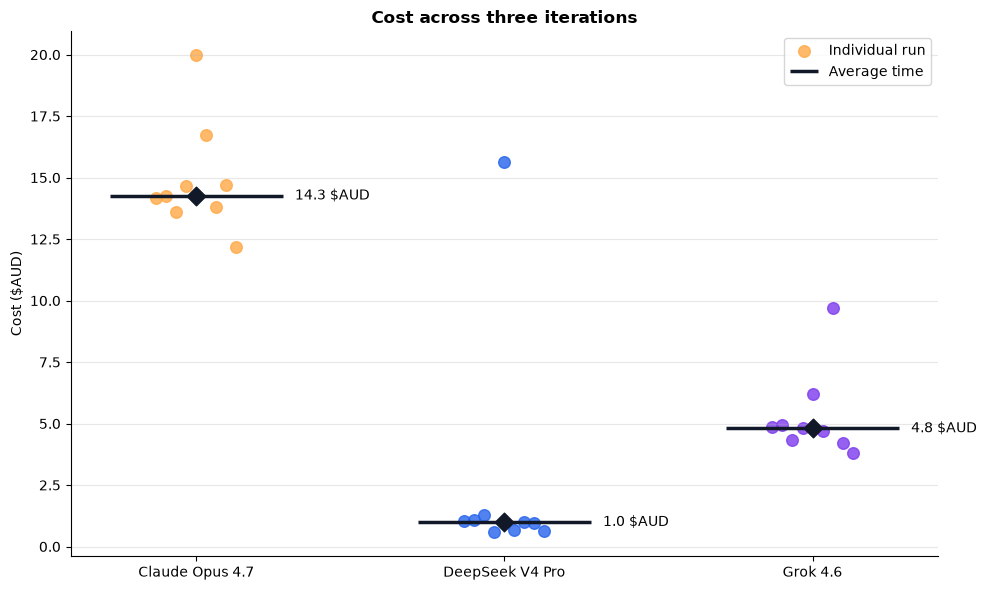

In [146]:
times = {
    "Claude Opus 4.7": COST_ITERATIONS["Claude"],
    "DeepSeek V4 Pro": COST_ITERATIONS['DeepSeek'],
    "Grok 4.6": COST_ITERATIONS['Grok'],
}

plot_dot_with_median(times, "Cost across three iterations", "Cost ($AUD)", unit="$AUD")

## 4.2 Benchmark the time taken between three iterations per LLM

Which model takes the longest time to complete an assessment.

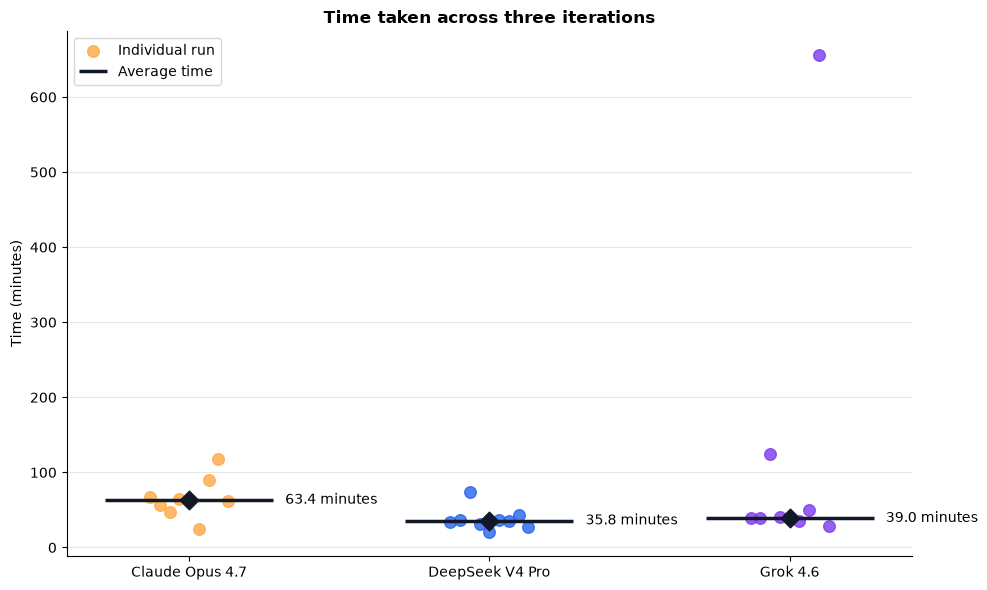

In [145]:
times = {
    "Claude Opus 4.7": TIME_ITERATIONS["Claude"],
    "DeepSeek V4 Pro":  TIME_ITERATIONS["DeepSeek"],
    "Grok 4.6":  TIME_ITERATIONS["Grok"],
}

plot_dot_with_median(times, "Time taken across three iterations", "Time (minutes)", unit="minutes")

## 4.3 Consistency evaluation methodology across iterations for each LLM 
Checking the consistency of vulnerabilities discovery, their severity consistency and known-bug recall rate. However, severity consistency can only be eligable in cases where that specific bug is found `AT LEAST` twice during the entire process. If only one iteration detects the bug or none at all, it will be excluded.
For all bugs, the consistency can be calculated based on the previous dataset using the following formulas:
### 4.3.1 Known-bug recall formula

$$
\text{Known-bug recall}
=
\mathrm{KBR}_{m,r}
=
\frac{\left|F_{m,r} \cap K\right|}{\left|K\right|}
\times 100
=
\frac{
\text{Number of known bugs found in one run}
}{
\text{Total number of known bugs expected}
}
\times 100
$$

$$
\text{Average known-bug recall}
=
\overline{\mathrm{KBR}}_{m}
=
\frac{1}{N}
\sum_{r=1}^{N}
\mathrm{KBR}_{m,r}
=
\frac{
\text{Recall in Run 1} + \text{Recall in Run 2} + \text{Recall in Run 3}
}{
\text{Number of runs}
}
$$

### 4.3.2 Discoveries consistency formula

For one specific bug:

$$
\text{Discovery consistency}
=
\mathrm{DC}_{m,b}
=
\frac{
\sum_{r=1}^{N}
\mathbb{1}\left\{b \in F_{m,r}\right\}
}{
N
}
\times 100
=
\frac{
\text{Number of runs in which that bug was found}
}{
\text{Total number of runs}
}
\times 100
$$

For the whole model:

$$
\text{Overall discovery consistency}
=
\mathrm{DC}_{m}
=
\frac{1}{\left|B\right|}
\sum_{b \in B}
\mathrm{DC}_{m,b}
=
\frac{
\text{Sum of every bug's discovery-consistency score}
}{
\text{Number of bugs assessed}
}
$$

Use \(B = K\) when assessing known bugs only. Alternatively, use \(B\) as the set of known and validated new bugs.


### 4.3.3 Severity consistency formula

For one specific bug:

$$
\text{Severity consistency}
=
\mathrm{SC}_{m,b}
=
\frac{
\max_{s \in \mathcal{S}}
\left[
\sum_{r=1}^{N}
\mathbb{1}
\left\{
b \in F_{m,r}
\land
S_{m,b,r} = s
\right\}
\right]
}{
n_{m,b}
}
\times 100
=
\frac{
\text{Number of times the most common severity was assigned}
}{
\text{Number of runs where that bug was found}
}
\times 100
$$

For the whole model:

$$
\text{Overall severity consistency}
=
\mathrm{SC}_{m}
=
\frac{1}{\left|B_m^{*}\right|}
\sum_{b \in B_m^{*}}
\mathrm{SC}_{m,b}
=
\frac{
\text{Sum of every bug's severity-consistency score}
}{
\text{Number of bugs found in at least two runs}
}
$$

Where \(B_m^{*}\) is the set of bugs found by model \(m\) in at least two runs. This prevents a bug found only once from appearing automatically 100% severity-consistent.


## Notes
- However, this research mainly focuses on evaluating the consistency for an entire model instead of specific vulnerability
- You will first need to calculate the initial consistency per bug. Then based on the gained results, you will be able to calculate the overall consistency rate for an entire model. 

## 4.4 Consistency for severity and discovery rate for known bugs (Table)

In [76]:
# Duplicate the dataframe
consistency = df_results[['Vulnerability ID', 'Vulnerabilities', 'Severity']].copy()

# Extract all of the rows where it belongs to each LLM
claude_i = df_results.iloc[:, 4:7]    # Claude 
deepseek_i = df_results.iloc[:, 7:10] # DeepSeek
grok_i = df_results.iloc[:, 10:13]    # Grok

# Calculate the consistency value
iterations = 3
def sc_cal(llm_i):
    found_count = llm_i.notna().sum(axis=1)
    return llm_i.apply(lambda row: row.value_counts().max(), axis=1).div(found_count).mul(100).where(found_count >= 2)

consistency["Claude DC(%)"] = df_results.iloc[:, 4:7].notna().sum(axis=1) / iterations * 100
consistency['DeepSeek DC(%)'] = df_results.iloc[:, 7:10].notna().sum(axis=1) / iterations * 100
consistency['Grok DC(%)'] = df_results.iloc[:, 10:13].notna().sum(axis=1) / iterations * 100
consistency["Claude SC(%)"] = sc_cal(claude_i)
consistency['DeepSeek SC(%)'] = sc_cal(deepseek_i)
consistency['Grok SC(%)'] = sc_cal(grok_i)

consistency

,Vulnerability ID,Vulnerabilities,Severity,Claude DC(%),DeepSeek DC(%),Grok DC(%),Claude SC(%),DeepSeek SC(%),Grok SC(%)
0,1,/api/admin/login error-based SQLi,high,0.000000,0.000000,0.000000,NaN,NaN,NaN
1,2,/article/<slug>/comment error-based SQLi,high,0.000000,0.000000,0.000000,NaN,NaN,NaN
2,3,/category/<slug> conditional SQLi,high,0.000000,0.000000,0.000000,NaN,NaN,NaN
3,4,/article/<slug> conditional SQLi,high,0.000000,0.000000,0.000000,NaN,NaN,NaN
4,5,"IDOR via ""article_id""",high,33.333333,0.000000,0.000000,NaN,NaN,NaN
5,6,OS Command Injection via search,critical,0.000000,0.000000,0.000000,NaN,NaN,NaN
6,7,/api/article/<slug> SSTI,critical,0.000000,0.000000,0.000000,NaN,NaN,NaN
7,8,/article/<slug> SSTI,critical,0.000000,0.000000,33.333333,NaN,NaN,NaN
8,9,/search?q SSTI,critical,66.666667,33.333333,66.666667,100.000000,NaN,100.000000
9,10,Unencrypted FTP connection,medium,66.666667,0.000000,33.333333,50.000000,NaN,NaN


## 4.4 Consistency for severity and discovery rate for new bugs (Table)

In [78]:
df_new_bugs

,Unnamed: 0,DeepSeek V4 Pro,Unnamed: 2,Unnamed: 3,Grok 4.6,Unnamed: 5,Unnamed: 6,Claude Opus 4.7,Unnamed: 8,Unnamed: 9,...,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Claude Opus 4.7.1,DeepSeek V4 Pro.1,DeepSeek V4 Pro I2,DeepSeek V4 Pro I3,Grok 4.6.1
0,NaN,1,2,3,1,2,3,1,2,3,...,NaN,NaN,NaN,NaN,False-positive,1,0,0,0,0
1,Company 6,osticket installer exposed,osticket installer exposed,osticket installer exposed,osticket installer exposed,osticket installer exposed,admin dashboard exposed without authentication...,osticket installer exposed,osticket installer exposed,osticket installer exposed,...,NaN,NaN,NaN,NaN,New bugs,7,12,9,10,13
2,NaN,pii exposure on admin dashboard,admin dashboard exposed without authentication...,admin dashboard exposed without authentication...,missing http security headers,cors misconfiguration for http to https redirect,missing http security headers,"missing email security records (spf, caa, dmar...","missing email security records (spf, caa, dmar...",ssh allows password login,...,NaN,NaN,NaN,NaN,Out-of-scoped,0,0,0,0,0
3,NaN,wordpress directory listing enabled,apache site exposed on port 8080 via cleartext,wordpress directory listing enabled,"missing email security records (spf, caa, dmar...",open dns resolvers for all servers,"missing email security records (spf, caa, dmar...",wordpress xml-rpc enabled,apache site exposed on port 8080 via cleartext,apache site exposed on port 8080 via cleartext,...,NaN,NaN,NaN,NaN,NaN,False-positives,New bugs,Out-of-scope,NaN,NaN
4,NaN,wordpress user enumeration enabled,missing http security headers,missing http security headers,wordpress xml-rpc enabled,wordpress xml-rpc enabled,/api path redirects to http,osticket cooke missing security flags,pii exposure on admin dashboard,"missing email security records (spf, caa, dmar...",...,NaN,NaN,NaN,NaN,Claude Opus 4.7,1,7,0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
62,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
63,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
64,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4.4 Consistency evaluation for known-bugs

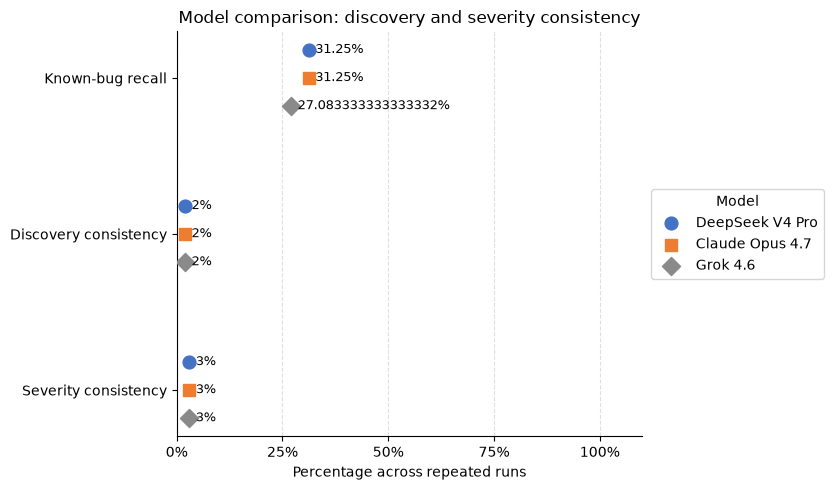

(<Figure size 1000x500 with 1 Axes>,
 <Axes: title={'center': 'Model comparison: discovery and severity consistency'}, xlabel='Percentage across repeated runs'>)

In [17]:
# Analyse the raw results
iterations = 3

# Calculating overall consistency for known-bug recall
opportunities = df_results['Severity'].count() * iterations
claude_kb = ((df_results['Claude Opus 4.7 I1'].count()+ df_results['Claude Opus 4.7 I2'].count()+df_results['Claude Opus 4.7 I3'].count() ) / opportunities) * 100
deepseek_kb = ((df_results['DeepSeek V4 Pro I1'].count()+ df_results['DeepSeek V4 Pro I2'].count()+df_results['DeepSeek V4 Pro I3'].count() ) / opportunities) * 100
grok_kb = ((df_results['Grok 4.6 I1'].count()+ df_results['Grok 4.6 I2'].count()+df_results['Grok 4.6 I3'].count() ) / opportunities) * 100

# Calculating discovery consistency
bug_discovery_consistency = {
    f"{bugID}":{"claude":0, "deepseek":0, "grok":0} for bugID in list(df_results["Vulnerability ID"])
}

# Calculating severity consistency
consistency_known_bugs = (
    [deepseek_kb,2,3], # DeepSeek 
    [claude_kb,2,3], # Claude
    [grok_kb,2,3] # Grok
)
metrics = {
    "Known-bug recall": {
        "DeepSeek V4 Pro": deepseek_kb,
        "Claude Opus 4.7": claude_kb,
        "Grok 4.6": grok_kb,
    },
    "Discovery consistency": {
        "DeepSeek V4 Pro": consistency_known_bugs[0][1],
        "Claude Opus 4.7": consistency_known_bugs[1][1],
        "Grok 4.6": consistency_known_bugs[2][1],
    },
    "Severity consistency": {
        "DeepSeek V4 Pro": consistency_known_bugs[0][2],
        "Claude Opus 4.7": consistency_known_bugs[1][2],
        "Grok 4.6": consistency_known_bugs[2][2],
    },
}

plot_model_summary(metrics)

## 4.5 Consistency rate for each bug for every model
Show a table here with all of the analysis

## 4.3 Consistency evaluation across iterations for each LLM (new bugs)
Checking the consistency of new discoveries as well as their severity.

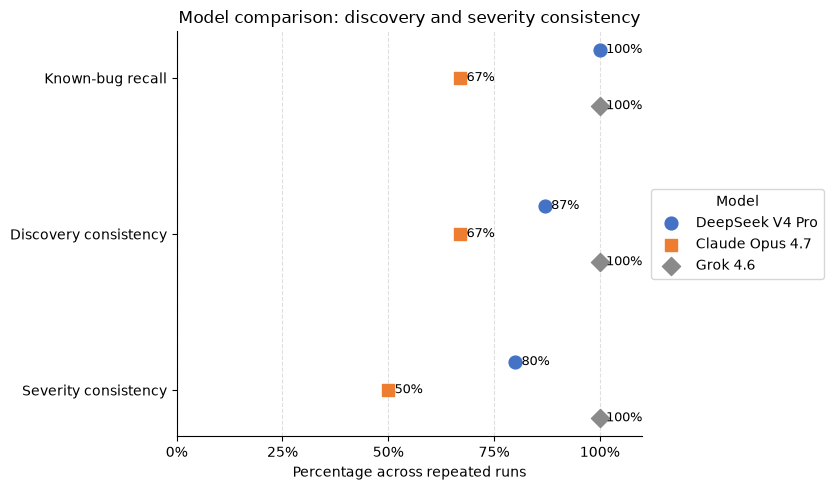

(<Figure size 1000x500 with 1 Axes>,
 <Axes: title={'center': 'Model comparison: discovery and severity consistency'}, xlabel='Percentage across repeated runs'>)

In [70]:
metrics = {
    "Known-bug recall": {
        "DeepSeek V4 Pro": 100,
        "Claude Opus 4.7": 67,
        "Grok 4.6": 100,
    },
    "Discovery consistency": {
        "DeepSeek V4 Pro": 87,
        "Claude Opus 4.7": 67,
        "Grok 4.6": 100,
    },
    "Severity consistency": {
        "DeepSeek V4 Pro": 80,
        "Claude Opus 4.7": 50,
        "Grok 4.6": 100,
    },
}

plot_model_summary(metrics)

# 5 Additional findings
---
Not what relevant to the above but more like insights collected from the dataset

1. There was one outlier in Grok 4.6 during iteration 2 of company `AuSecurity` where it took over 600 minutes.
2. There was one outlier in DeepSeek V4 Pro during Iteration 2 of the company `Imagur` where it costed over 15 dollars and was hanging over night during the assessment. I had to manually stop the assessment and restarted it.
3. Claude finds the most bugs but DeepSeek finds the most intentional bugs
4. Grok 4.6 experienced outliers in execution time and poorly perform at enumerating for public assets